<a href="https://colab.research.google.com/github/SAMANVI-MEDARAMETLA/Fundamental-of-Machine-Learning-/blob/main/FOML_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Experiment 1: FIND-S Algorithm

import pandas as pd

# Training data
data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Weak'],
    'Water': ['Warm', 'Warm', 'Warm', 'Warm'],
    'Forecast': ['Same', 'Same', 'Change', 'Change'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)

print("Training Data:")
print(df)

# FIND-S algorithm
hypothesis = ['Ø'] * 6

for i in range(len(df)):
    if df.iloc[i]['EnjoySport'] == 'Yes':
        for j in range(6):
            if hypothesis[j] == 'Ø':
                hypothesis[j] = df.iloc[i, j]
            elif hypothesis[j] != df.iloc[i, j]:
                hypothesis[j] = '?'

print("\nMost Specific Hypothesis:")
print(hypothesis)

Training Data:
     Sky AirTemp Humidity    Wind Water Forecast EnjoySport
0  Sunny    Warm   Normal  Strong  Warm     Same        Yes
1  Sunny    Warm     High  Strong  Warm     Same        Yes
2  Rainy    Cold     High  Strong  Warm   Change         No
3  Sunny    Warm     High    Weak  Warm   Change        Yes

Most Specific Hypothesis:
['Sunny', 'Warm', '?', '?', 'Warm', '?']


In [ ]:
# Experiment 2: Candidate-Elimination Algorithm

import pandas as pd

# Create training data
data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Weak'],
    'Water': ['Warm', 'Warm', 'Warm', 'Warm'],
    'Forecast': ['Same', 'Same', 'Change', 'Change'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
}

# Convert data into DataFrame
df = pd.DataFrame(data)

# Save as CSV
df.to_csv('training_data.csv', index=False)

# Read CSV file
df = pd.read_csv('training_data.csv')

print("Training Data:")
print(df)

# Attributes
attributes = list(df.columns[:-1])
n = len(attributes)

# Initial Specific and General hypotheses
S = ['Ø'] * n
G = [['?'] * n]

# Candidate-Elimination Algorithm
for i in range(len(df)):

    example = list(df.iloc[i][:-1])
    target = df.iloc[i][-1]

    # Positive example
    if target == 'Yes':

        for j in range(n):

            if S[j] == 'Ø':
                S[j] = example[j]

            elif S[j] != example[j]:
                S[j] = '?'

        # Remove inconsistent hypotheses from G
        G = [
            g for g in G
            if all(g[j] == '?' or g[j] == S[j] for j in range(n))
        ]

    # Negative example
    else:

        new_G = []

        for g in G:

            for j in range(n):

                if g[j] == '?' and S[j] != '?' and S[j] != 'Ø':

                    new_g = g.copy()
                    new_g[j] = S[j]

                    if new_g not in new_G:
                        new_G.append(new_g)

        G = new_G

# Display results
print("\nSpecific Boundary (S):")
print(S)

print("\nGeneral Boundary (G):")
for g in G:
    print(g)

Training Data:
     Sky AirTemp Humidity    Wind Water Forecast EnjoySport
0  Sunny    Warm   Normal  Strong  Warm     Same        Yes
1  Sunny    Warm     High  Strong  Warm     Same        Yes
2  Rainy    Cold     High  Strong  Warm   Change         No
3  Sunny    Warm     High    Weak  Warm   Change        Yes

Specific Boundary (S):
['Sunny', 'Warm', '?', '?', 'Warm', '?']

General Boundary (G):
['Sunny', '?', '?', '?', '?', '?']
['?', 'Warm', '?', '?', '?', '?']
['?', '?', '?', '?', 'Warm', '?']


/tmp/ipykernel_1351/3065246598.py:40: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  target = df.iloc[i][-1]


Training Data:
     Outlook Temperature Humidity  Windy Play
0      Sunny         Hot     High  False   No
1      Sunny         Hot     High   True   No
2   Overcast         Hot     High  False  Yes
3       Rain        Mild     High  False  Yes
4       Rain        Cool   Normal  False  Yes
5       Rain        Cool   Normal   True   No
6   Overcast        Cool   Normal   True  Yes
7      Sunny        Mild     High  False   No
8      Sunny        Cool   Normal  False  Yes
9       Rain        Mild   Normal  False  Yes
10     Sunny        Mild   Normal   True  Yes
11  Overcast        Mild     High   True  Yes
12  Overcast         Hot   Normal  False  Yes
13      Rain        Mild     High   True   No

Prediction for new sample:
No


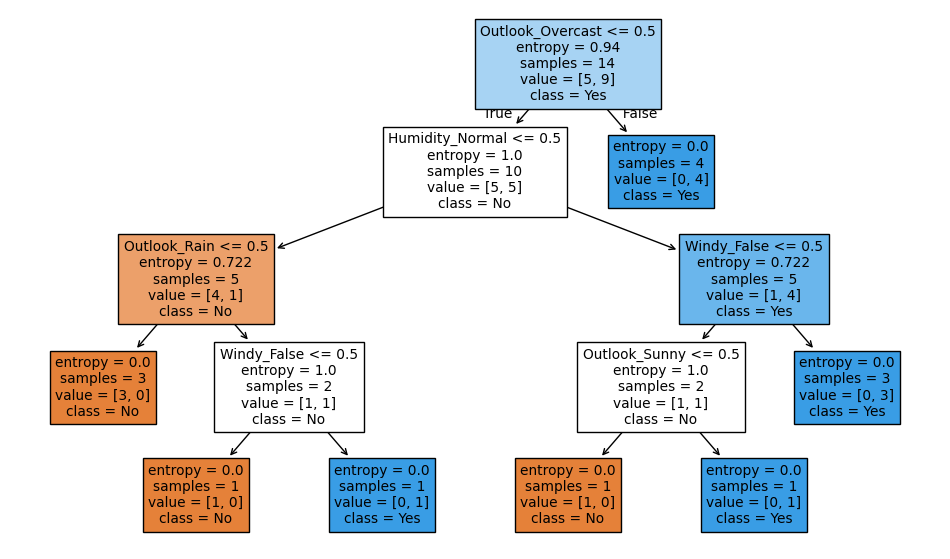

In [ ]:
# Experiment 3: Decision Tree using ID3

import pandas as pd
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

# Training data
data = {
    'Outlook': ['Sunny', 'Sunny', 'Overcast', 'Rain', 'Rain',
                'Rain', 'Overcast', 'Sunny', 'Sunny', 'Rain',
                'Sunny', 'Overcast', 'Overcast', 'Rain'],

    'Temperature': ['Hot', 'Hot', 'Hot', 'Mild', 'Cool',
                    'Cool', 'Cool', 'Mild', 'Cool', 'Mild',
                    'Mild', 'Mild', 'Hot', 'Mild'],

    'Humidity': ['High', 'High', 'High', 'High', 'Normal',
                 'Normal', 'Normal', 'High', 'Normal', 'Normal',
                 'Normal', 'High', 'Normal', 'High'],

    'Windy': ['False', 'True', 'False', 'False', 'False',
              'True', 'True', 'False', 'False', 'False',
              'True', 'True', 'False', 'True'],

    'Play': ['No', 'No', 'Yes', 'Yes', 'Yes',
             'No', 'Yes', 'No', 'Yes', 'Yes',
             'Yes', 'Yes', 'Yes', 'No']
}

df = pd.DataFrame(data)

print("Training Data:")
print(df)

# Convert categorical data into numbers
X = pd.get_dummies(df.drop('Play', axis=1))
y = df['Play']

# Create Decision Tree using ID3
model = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

# Train the model
model.fit(X, y)

# Predict a new sample
new_sample = pd.DataFrame({
    'Outlook': ['Sunny'],
    'Temperature': ['Cool'],
    'Humidity': ['High'],
    'Windy': ['True']
})

new_sample = pd.get_dummies(new_sample)
new_sample = new_sample.reindex(columns=X.columns, fill_value=0)

prediction = model.predict(new_sample)

print("\nPrediction for new sample:")
print(prediction[0])

# Display decision tree
plt.figure(figsize=(12, 7))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True
)
plt.show()

Dataset shape: (150, 4)
Classes: ['setosa' 'versicolor' 'virginica']

Training samples: 120
Testing samples: 30

Actual values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Predicted values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]

Accuracy: 0.9666666666666667
Accuracy percentage: 96.66666666666667 %

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



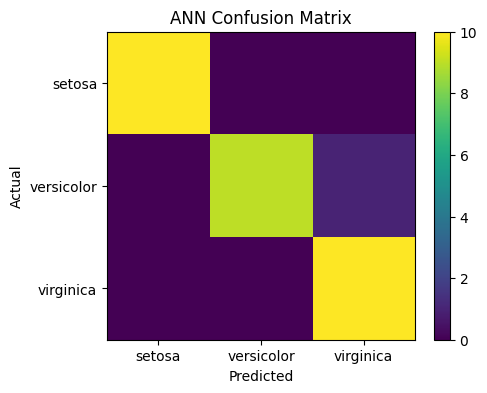

In [ ]:
# EX-4: Artificial Neural Network using Backpropagation

# Step 1: Import libraries
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Step 2: Load Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

print("Dataset shape:", X.shape)
print("Classes:", iris.target_names)

# Step 3: Split data into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

# Step 4: Standardize the data
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Step 5: Create Artificial Neural Network
model = MLPClassifier(
    hidden_layer_sizes=(10,),
    activation='relu',
    solver='adam',
    learning_rate_init=0.01,
    max_iter=1000,
    random_state=42
)

# Step 6: Train the ANN
model.fit(X_train, y_train)

# Step 7: Predict test data
y_pred = model.predict(X_test)

# Step 8: Display actual and predicted values
print("\nActual values:")
print(y_test)

print("\nPredicted values:")
print(y_pred)

# Step 9: Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", accuracy)
print("Accuracy percentage:", accuracy * 100, "%")

# Step 10: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# Step 11: Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

# Step 12: Display Confusion Matrix
plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("ANN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()

plt.xticks([0, 1, 2], iris.target_names)
plt.yticks([0, 1, 2], iris.target_names)

plt.show()

In [ ]:

# EX-5: K-Nearest Neighbours (KNN)

# Step 1: Import libraries
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# Step 2: Load dataset
iris = load_iris()
X = iris.data
y = iris.target

# Step 3: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 4: Create KNN model
model = KNeighborsClassifier(n_neighbors=3)

# Step 5: Train model
model.fit(X_train, y_train)

# Step 6: Predict test data
y_pred = model.predict(X_test)

# Step 7: Display results
print("Actual values:")
print(y_test)

print("\nPredicted values:")
print(y_pred)

# Step 8: Calculate accuracy
print("\nAccuracy:", accuracy_score(y_test, y_pred))

# Step 9: Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Actual values:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]

Predicted values:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]

Accuracy: 1.0

Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


In [ ]:

# EX-6: Naive Bayes Classification

# Step 1: Import libraries
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix

# Step 2: Load dataset
iris = load_iris()
X = iris.data
y = iris.target

# Step 3: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 4: Create Naive Bayes model
model = GaussianNB()

# Step 5: Train model
model.fit(X_train, y_train)

# Step 6: Predict test data
y_pred = model.predict(X_test)

# Step 7: Display results
print("Actual values:")
print(y_test)

print("\nPredicted values:")
print(y_pred)

# Step 8: Calculate accuracy
print("\nAccuracy:", accuracy_score(y_test, y_pred))

# Step 9: Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Actual values:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]

Predicted values:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]

Accuracy: 1.0

Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


In [ ]:

# EX-7: Logistic Regression

# Step 1: Import libraries
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# Step 2: Load dataset
iris = load_iris()
X = iris.data
y = iris.target

# Step 3: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 4: Create Logistic Regression model
model = LogisticRegression(max_iter=200)

# Step 5: Train model
model.fit(X_train, y_train)

# Step 6: Predict test data
y_pred = model.predict(X_test)

# Step 7: Display actual and predicted values
print("Actual values:")
print(y_test)

print("\nPredicted values:")
print(y_pred)

# Step 8: Calculate accuracy
print("\nAccuracy:", accuracy_score(y_test, y_pred))

# Step 9: Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Actual values:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]

Predicted values:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]

Accuracy: 1.0

Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


Actual values: [ 2  4  6  8 10]
Predicted values: [ 2.  4.  6.  8. 10.]
Slope: 2.0
Intercept: 0.0
Mean Squared Error: 0.0
R2 Score: 1.0
Prediction for X = 6: 12.0


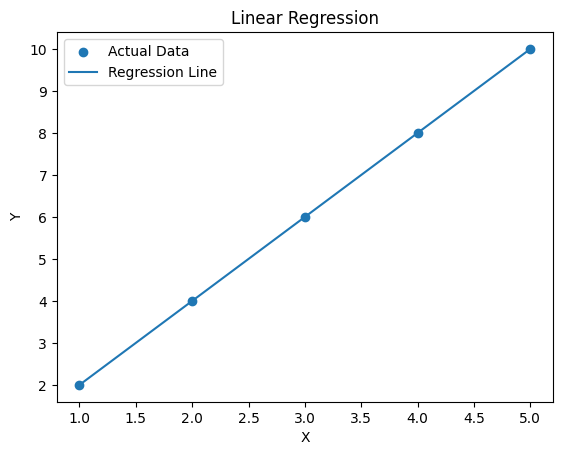

In [ ]:

# EX-8: Linear Regression

# Step 1: Import libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Step 2: Create dataset
X = np.array([[1], [2], [3], [4], [5]])
y = np.array([2, 4, 6, 8, 10])

# Step 3: Create Linear Regression model
model = LinearRegression()

# Step 4: Train model
model.fit(X, y)

# Step 5: Predict values
y_pred = model.predict(X)

# Step 6: Display results
print("Actual values:", y.ravel() if y.ndim > 1 else y)
print("Predicted values:", y_pred)
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

# Step 7: Calculate evaluation metrics
print("Mean Squared Error:", mean_squared_error(y, y_pred))
print("R2 Score:", r2_score(y, y_pred))

# Step 8: Predict a new value
new_value = model.predict([[6]])
print("Prediction for X = 6:", new_value[0])

# Step 9: Plot regression line
plt.scatter(X, y, label="Actual Data")
plt.plot(X, y_pred, label="Regression Line")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Linear Regression")
plt.legend()
plt.show()


Linear Regression Predictions: [-1.33  5.67 12.67 19.67 26.67 33.67]
Polynomial Regression Predictions: [ 2.  5. 10. 17. 26. 37.]
Linear Regression MSE: 6.22
Polynomial Regression MSE: 0.0
Linear Regression R2 Score: 0.96
Polynomial Regression R2 Score: 1.0


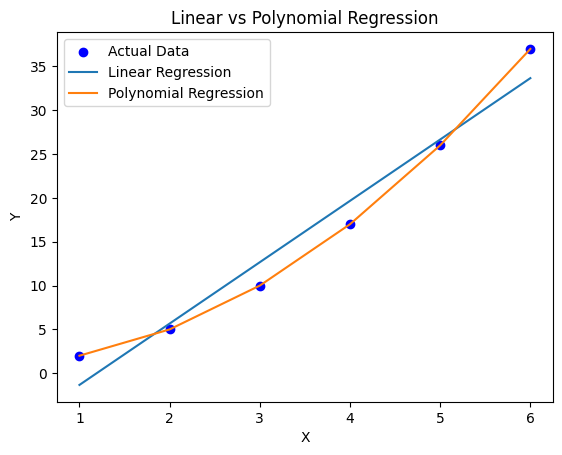

In [ ]:
#EX-9
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

# Sample dataset
X = np.array([1, 2, 3, 4, 5, 6]).reshape(-1, 1)
y = np.array([2, 5, 10, 17, 26, 37])

# Linear Regression
linear_model = LinearRegression()
linear_model.fit(X, y)
linear_pred = linear_model.predict(X)

# Polynomial Regression (degree 2)
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)
poly_model = LinearRegression()
poly_model.fit(X_poly, y)
poly_pred = poly_model.predict(X_poly)

# Display results
print("Linear Regression Predictions:", np.round(linear_pred, 2))
print("Polynomial Regression Predictions:", np.round(poly_pred, 2))
print("Linear Regression MSE:", round(mean_squared_error(y, linear_pred), 2))
print("Polynomial Regression MSE:", round(mean_squared_error(y, poly_pred), 2))
print("Linear Regression R2 Score:", round(r2_score(y, linear_pred), 2))
print("Polynomial Regression R2 Score:", round(r2_score(y, poly_pred), 2))

# Plot the results
plt.scatter(X, y, color="blue", label="Actual Data")
plt.plot(X, linear_pred, label="Linear Regression")
plt.plot(X, poly_pred, label="Polynomial Regression")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.show()


Number of clusters: 3
Cluster labels: [0 1 2]
First 10 predicted labels: [1 2 0 2 1 2 0 2 2 0]
Model converged: True


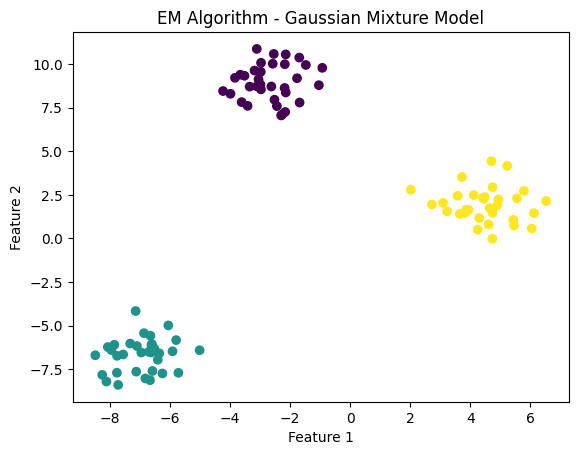

In [ ]:
#EX-10
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from sklearn.datasets import make_blobs

# Generate sample data
X, y = make_blobs(n_samples=100, centers=3, random_state=42)

# Apply EM algorithm using Gaussian Mixture Model
model = GaussianMixture(n_components=3, random_state=42)
model.fit(X)

# Predict clusters
labels = model.predict(X)

print("Number of clusters:", model.n_components)
print("Cluster labels:", np.unique(labels))
print("First 10 predicted labels:", labels[:10])
print("Model converged:", model.converged_)

# Visualize clusters
plt.scatter(X[:, 0], X[:, 1], c=labels)
plt.title("EM Algorithm - Gaussian Mixture Model")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


In [ ]:
#EX-11
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create sample credit score dataset
data = {
    "Income": [30000, 50000, 70000, 25000, 80000, 60000, 35000, 90000, 45000, 75000],
    "Loan": [10000, 15000, 10000, 20000, 5000, 12000, 18000, 8000, 16000, 7000],
    "Payment_History": [2, 3, 3, 1, 3, 2, 1, 3, 2, 3],
    "Credit_Score": ["Poor", "Standard", "Good", "Poor", "Good",
                     "Standard", "Poor", "Good", "Standard", "Good"]
}

df = pd.DataFrame(data)

# Separate features and target
X = df[["Income", "Loan", "Payment_History"]]
y = df["Credit_Score"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Train model
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

# Predict and evaluate
y_pred = model.predict(X_test)

print("Actual Credit Scores:", list(y_test))
print("Predicted Credit Scores:", list(y_pred))
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

# Predict credit score for a new person
new_person = pd.DataFrame({
    "Income": [65000],
    "Loan": [10000],
    "Payment_History": [3]
})

print("New Person's Predicted Credit Score:", model.predict(new_person)[0])


Actual Credit Scores: ['Standard', 'Standard', 'Standard']
Predicted Credit Scores: ['Poor', 'Good', 'Poor']
Accuracy: 0.0 %
New Person's Predicted Credit Score: Good


In [ ]:
#EX-12
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train KNN model
model = KNeighborsClassifier(n_neighbors=3)
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

print("Actual Values:", y_test)
print("Predicted Values:", y_pred)
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n",
      classification_report(y_test, y_pred, target_names=iris.target_names))

# Predict a new flower
new_flower = [[5.1, 3.5, 1.4, 0.2]]
prediction = model.predict(new_flower)
print("Predicted Flower:", iris.target_names[prediction[0]])


Actual Values: [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]
Predicted Values: [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]
Accuracy: 100.0 %
Confusion Matrix:
 [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Predicted Flower: setosa


In [1]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create sample car dataset
data = {
    "Age": [1, 2, 3, 4, 5, 6, 2, 3, 5, 7],
    "Mileage": [10000, 20000, 30000, 40000, 50000,
                60000, 15000, 25000, 45000, 70000],
    "Engine_Size": [1200, 1200, 1500, 1500, 1800,
                    1800, 1200, 1500, 1800, 2000],
    "Price": [900000, 800000, 700000, 600000, 500000,
              400000, 820000, 730000, 520000, 350000]
}

df = pd.DataFrame(data)

# Separate input and output
X = df[["Age", "Mileage", "Engine_Size"]]
y = df["Price"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict car prices
y_pred = model.predict(X_test)

print("Actual Car Prices:", list(y_test))
print("Predicted Car Prices:", y_pred.round(2))
print("Mean Absolute Error:", round(mean_absolute_error(y_test, y_pred), 2))
print("Mean Squared Error:", round(mean_squared_error(y_test, y_pred), 2))
print("R2 Score:", round(r2_score(y_test, y_pred), 2))

# Predict price of a new car
new_car = pd.DataFrame({
    "Age": [2],
    "Mileage": [18000],
    "Engine_Size": [1500]
})

predicted_price = model.predict(new_car)
print("Predicted Price of New Car: ₹", round(predicted_price[0], 2))


Actual Car Prices: [520000, 800000]
Predicted Car Prices: [544261.6  789810.13]
Mean Absolute Error: 17225.74
Mean Squared Error: 346229459.31
R2 Score: 0.98
Predicted Price of New Car: ₹ 813641.35


In [2]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create sample house dataset
data = {
    "Area": [1000, 1200, 1500, 1800, 2000, 2200, 2500, 2800, 3000, 1600],
    "Bedrooms": [2, 2, 3, 3, 4, 4, 4, 5, 5, 3],
    "Age": [10, 8, 5, 4, 3, 2, 1, 2, 1, 6],
    "Price": [3000000, 3500000, 4500000, 5000000, 6000000,
              6500000, 7500000, 8000000, 9000000, 4800000]
}

df = pd.DataFrame(data)

# Separate input and output
X = df[["Area", "Bedrooms", "Age"]]
y = df["Price"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict house prices
y_pred = model.predict(X_test)

print("Actual House Prices:", list(y_test))
print("Predicted House Prices:", y_pred.round(2))
print("Mean Absolute Error:", round(mean_absolute_error(y_test, y_pred), 2))
print("Mean Squared Error:", round(mean_squared_error(y_test, y_pred), 2))
print("R2 Score:", round(r2_score(y_test, y_pred), 2))

# Predict price of a new house
new_house = pd.DataFrame({
    "Area": [1800],
    "Bedrooms": [3],
    "Age": [2]
})

predicted_price = model.predict(new_house)
print("Predicted House Price: ₹", round(predicted_price[0], 2))


Actual House Prices: [9000000, 3500000]
Predicted House Prices: [8642289.11 3518803.42]
Mean Absolute Error: 188257.15
Mean Squared Error: 64155324028.33
R2 Score: 0.99
Predicted House Price: ₹ 5377740.62


In [3]:

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train Naive Bayes model
model = GaussianNB()
model.fit(X_train, y_train)

# Predict flower species
y_pred = model.predict(X_test)

# Display results
print("Actual Values:", y_test)
print("Predicted Values:", y_pred)
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n",
      classification_report(y_test, y_pred, target_names=iris.target_names))

# Predict a new flower
new_flower = [[5.1, 3.5, 1.4, 0.2]]
prediction = model.predict(new_flower)

print("Predicted Flower:", iris.target_names[prediction[0]])


Actual Values: [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]
Predicted Values: [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]
Accuracy: 100.0 %
Confusion Matrix:
 [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Predicted Flower: setosa


In [4]:

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
import pandas as pd

# Load Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Define classification algorithms
models = {
    "KNN": KNeighborsClassifier(n_neighbors=3),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Naive Bayes": GaussianNB(),
    "Logistic Regression": LogisticRegression(max_iter=200),
    "SVM": SVC()
}

# Train and compare models
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred) * 100
    results.append([name, round(accuracy, 2)])

# Display comparison
df = pd.DataFrame(results, columns=["Algorithm", "Accuracy (%)"])

print("Classification Algorithm Comparison")
print(df.to_string(index=False))

# Find best algorithm
best = df.loc[df["Accuracy (%)"].idxmax()]
print("\nBest Algorithm:", best["Algorithm"])
print("Best Accuracy:", best["Accuracy (%)"], "%")


Classification Algorithm Comparison
          Algorithm  Accuracy (%)
                KNN         100.0
      Decision Tree         100.0
        Naive Bayes         100.0
Logistic Regression         100.0
                SVM         100.0

Best Algorithm: KNN
Best Accuracy: 100.0 %


In [5]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create sample mobile dataset
data = {
    "RAM": [2, 3, 4, 6, 8, 12, 2, 4, 6, 8, 3, 12],
    "Battery": [2500, 3000, 3500, 4000, 4500, 5000,
                2800, 3600, 4200, 4800, 3200, 5200],
    "Internal_Memory": [16, 32, 64, 64, 128, 256,
                        16, 64, 128, 128, 32, 256],
    "Screen_Size": [5.0, 5.2, 5.5, 6.0, 6.2, 6.7,
                    5.1, 5.6, 6.1, 6.5, 5.3, 6.8],
    "Price_Range": [0, 0, 1, 1, 2, 3, 0, 1, 2, 3, 0, 3]
}

df = pd.DataFrame(data)

# Separate features and target
X = df[["RAM", "Battery", "Internal_Memory", "Screen_Size"]]
y = df["Price_Range"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# Train Random Forest model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Predict price range
y_pred = model.predict(X_test)

print("Actual Price Ranges:", list(y_test))
print("Predicted Price Ranges:", list(y_pred))
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:\n",
      classification_report(y_test, y_pred, zero_division=0))

# Predict price range for a new mobile
new_mobile = pd.DataFrame({
    "RAM": [8],
    "Battery": [5000],
    "Internal_Memory": [128],
    "Screen_Size": [6.5]
})

prediction = model.predict(new_mobile)
price_ranges = {
    0: "Low Cost",
    1: "Medium Cost",
    2: "High Cost",
    3: "Very High Cost"
}

print("Predicted Mobile Price Range:", price_ranges[prediction[0]])


Actual Price Ranges: [0, 3, 0]
Predicted Price Ranges: [np.int64(0), np.int64(2), np.int64(0)]
Accuracy: 66.67 %

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           2       0.00      0.00      0.00         0
           3       0.00      0.00      0.00         1

    accuracy                           0.67         3
   macro avg       0.33      0.33      0.33         3
weighted avg       0.67      0.67      0.67         3

Predicted Mobile Price Range: High Cost


In [6]:

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train Perceptron model
model = Perceptron(max_iter=1000, eta0=0.1, random_state=42)
model.fit(X_train, y_train)

# Predict flower species
y_pred = model.predict(X_test)

# Display results
print("Actual Values:", y_test)
print("Predicted Values:", y_pred)
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

print("Classification Report:\n",
      classification_report(y_test, y_pred,
                            target_names=iris.target_names))

# Predict a new flower
new_flower = [[5.1, 3.5, 1.4, 0.2]]
prediction = model.predict(new_flower)

print("Predicted Flower:", iris.target_names[prediction[0]])


Actual Values: [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]
Predicted Values: [1 0 1 1 1 0 1 1 1 1 1 0 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 1 0 0]
Accuracy: 63.33 %
Confusion Matrix:
 [[10  0  0]
 [ 0  9  0]
 [ 0 11  0]]
Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.45      1.00      0.62         9
   virginica       0.00      0.00      0.00        11

    accuracy                           0.63        30
   macro avg       0.48      0.67      0.54        30
weighted avg       0.47      0.63      0.52        30

Predicted Flower: setosa


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [7]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Create sample bank loan dataset
data = {
    "Income": [25000, 40000, 60000, 80000, 30000,
               70000, 45000, 90000, 35000, 65000,
               50000, 75000],
    "Credit_Score": [500, 600, 700, 800, 550,
                     750, 620, 850, 580, 720,
                     650, 780],
    "Loan_Amount": [200000, 150000, 100000, 80000, 180000,
                    90000, 140000, 70000, 170000, 95000,
                    130000, 85000],
    "Employment_Years": [1, 3, 5, 8, 2, 7, 4, 10, 2, 6, 4, 9],
    "Loan_Status": [0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1]
}

df = pd.DataFrame(data)

# Separate features and target
X = df[["Income", "Credit_Score", "Loan_Amount", "Employment_Years"]]
y = df["Loan_Status"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Train Naive Bayes model
model = GaussianNB()
model.fit(X_train, y_train)

# Predict loan status
y_pred = model.predict(X_test)

# Display results
print("Actual Loan Status:", list(y_test))
print("Predicted Loan Status:", list(y_pred))
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Predict for a new applicant
new_applicant = pd.DataFrame({
    "Income": [70000],
    "Credit_Score": [750],
    "Loan_Amount": [100000],
    "Employment_Years": [6]
})

prediction = model.predict(new_applicant)

if prediction[0] == 1:
    print("Loan Prediction: Approved")
else:
    print("Loan Prediction: Rejected")


Actual Loan Status: [1, 0, 0]
Predicted Loan Status: [np.int64(1), np.int64(0), np.int64(0)]
Accuracy: 100.0 %
Confusion Matrix:
 [[2 0]
 [0 1]]
Loan Prediction: Approved


Actual Sales: [500, 150]
Predicted Sales: [500. 150.]
Mean Absolute Error: 0.0
Mean Squared Error: 0.0
R2 Score: 1.0
Predicted Future Sales: 600.0


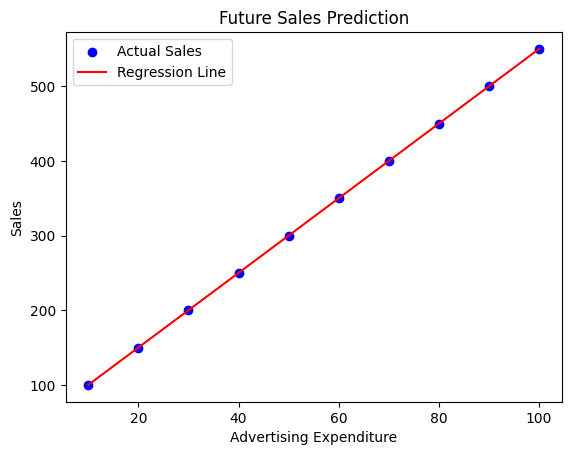

In [8]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create sample sales dataset
data = {
    "Advertising": [10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
    "Sales": [100, 150, 200, 250, 300, 350, 400, 450, 500, 550]
}

df = pd.DataFrame(data)

# Separate input and output
X = df[["Advertising"]]
y = df["Sales"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict sales
y_pred = model.predict(X_test)

# Display results
print("Actual Sales:", list(y_test))
print("Predicted Sales:", y_pred.round(2))
print("Mean Absolute Error:", round(mean_absolute_error(y_test, y_pred), 2))
print("Mean Squared Error:", round(mean_squared_error(y_test, y_pred), 2))
print("R2 Score:", round(r2_score(y_test, y_pred), 2))

# Predict future sales
future_advertising = pd.DataFrame({"Advertising": [110]})
future_sales = model.predict(future_advertising)

print("Predicted Future Sales:", round(future_sales[0], 2))

# Visualize results
plt.scatter(X, y, color="blue", label="Actual Sales")
plt.plot(X, model.predict(X), color="red", label="Regression Line")
plt.xlabel("Advertising Expenditure")
plt.ylabel("Sales")
plt.title("Future Sales Prediction")
plt.legend()
plt.show()
